# Stock Price Movement Predictor

## 1. Fetch Data
Download daily OHLCV history for a liquid equity (e.g., SPY) using `yfinance`.

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
from ta.momentum import RSIIndicator
from ta.trend import MACD, SMAIndicator
from ta.volatility import BollingerBands
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import os

os.makedirs('data', exist_ok=True)

ticker = "SPY"
raw_data = yf.download(ticker, start="1993-01-01", end="2024-09-01")

if isinstance(raw_data.columns, pd.MultiIndex):
    raw_data.columns = raw_data.columns.droplevel(1)

data = raw_data[['Open', 'High', 'Low', 'Close', 'Volume']].copy()
if 'Adj Close' in raw_data.columns:
    data['Close'] = raw_data['Adj Close']

data = data.sort_index(ascending=True)
data.to_csv('data/SPY_raw.csv')

print(f"Data fetched: {data.shape}")

[*********************100%***********************]  1 of 1 completed

Data fetched: (7954, 5)


## 3. Construct the target with zero leakage

`target = 1 if close.shift(-1) > close else 0`

We explicitly verify the label is shifted correctly by printing a sample of features and target.

In [2]:
data['target'] = (data['Close'].shift(-1) > data['Close']).astype(int)

# Print a sample of feature rows next to target labels to verify the shift
sample_check = data[['Close', 'target']].copy()
sample_check['Next_Close'] = data['Close'].shift(-1)
print("Leakage verification (target should correspond to Next_Close > Close):")
print(sample_check.head(10))

# Drop the final row because its target is undefined
data = data.dropna(subset=['target'])
# Wait, the last row of `shift(-1)` will be NaN before astype(int).
# Since `Close.shift(-1) > Close` evaluates to False for NaN if done naively, let's fix the logic:
data.loc[data.index[-1], 'target'] = np.nan
data = data.dropna(subset=['target'])
data['target'] = data['target'].astype(int)

# Compute class balance
print("\nClass Balance:")
print(data['target'].value_counts(normalize=True))

Leakage verification (target should correspond to Next_Close > Close):
Price           Close  target  Next_Close
Date                                     
1993-01-29  24.113264       1   24.284763
1993-02-01  24.284763       1   24.336203
1993-02-02  24.336203       1   24.593468
1993-02-03  24.593468       1   24.696362
1993-02-04  24.696362       0   24.679205
1993-02-05  24.679205       0   24.679205
1993-02-08  24.679205       0   24.507725
1993-02-09  24.507725       1   24.542004
1993-02-10  24.542004       1   24.662060
1993-02-11  24.662060       0   24.473427

Class Balance:
target
1    0.539545
0    0.460455
Name: proportion, dtype: float64


## 5. Build Two Feature Sets

**Raw Features:** OHLCV values and simple lagged returns.
**Engineered Features:** Computed using `ta` or pandas.

In [3]:
# Raw Features
raw_features = data[['Open', 'High', 'Low', 'Close', 'Volume']].copy()
# Simple lagged return
raw_features['Return_1d'] = raw_features['Close'].pct_change()

# Engineered Features
engineered_features = raw_features.copy()

# 1. RSI (Momentum)
rsi_indicator = RSIIndicator(close=engineered_features['Close'], window=14)
engineered_features['RSI'] = rsi_indicator.rsi()

# 2. MACD (Trend)
macd = MACD(close=engineered_features['Close'])
engineered_features['MACD'] = macd.macd()
engineered_features['MACD_Signal'] = macd.macd_signal()

# 3. Rolling Volatility (Volatility)
engineered_features['Rolling_Vol_20'] = engineered_features['Return_1d'].rolling(window=20).std()

# Drop NaNs from warmup
valid_indices = engineered_features.dropna().index
data = data.loc[valid_indices]
raw_features = raw_features.loc[valid_indices]
engineered_features = engineered_features.loc[valid_indices]
target = data['target']

## 6. Chronological Split & Scaling

~80% train / 20% test, split chronologically.

In [4]:
split_idx = int(len(data) * 0.8)
train_idx = data.index[:split_idx]
test_idx = data.index[split_idx:]

X_raw_train, X_raw_test = raw_features.loc[train_idx], raw_features.loc[test_idx]
X_eng_train, X_eng_test = engineered_features.loc[train_idx], engineered_features.loc[test_idx]
y_train, y_test = target.loc[train_idx], target.loc[test_idx]

# Scaling MUST be fit on train only!
scaler_raw = StandardScaler()
X_raw_train_scaled = scaler_raw.fit_transform(X_raw_train)
X_raw_test_scaled = scaler_raw.transform(X_raw_test)

scaler_eng = StandardScaler()
X_eng_train_scaled = scaler_eng.fit_transform(X_eng_train)
X_eng_test_scaled = scaler_eng.transform(X_eng_test)

## 4 & 7. Build Naive Baselines and Train Classifiers

In [5]:
# 1. Persistence Baseline: predict tomorrow's direction = today's realized direction
# Today's realized direction is (Close > Close.shift(1))
# This is known at time t.
persistence_preds = (data.loc[test_idx, 'Close'] > data.loc[test_idx, 'Close'].shift(1)).astype(int)
# Fix the first test prediction since shift might produce NaN if we only consider test_idx
persistence_preds.iloc[0] = (data.loc[test_idx[0], 'Close'] > data.loc[train_idx[-1], 'Close']).astype(int)

# 2. Majority Class Baseline: predict majority class from train set
majority_class = int(y_train.mode()[0])
majority_preds = np.full_like(y_test, fill_value=majority_class)

# Train Classifier on Raw Features
clf_raw = LogisticRegression(random_state=42)
clf_raw.fit(X_raw_train_scaled, y_train)
raw_preds = clf_raw.predict(X_raw_test_scaled)

# Train Classifier on Engineered Features
clf_eng = LogisticRegression(random_state=42)
clf_eng.fit(X_eng_train_scaled, y_train)
eng_preds = clf_eng.predict(X_eng_test_scaled)

## 8. Evaluate all four approaches

In [6]:
def evaluate_model(y_true, y_pred, name):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0)
    }

results = [
    evaluate_model(y_test, persistence_preds, "Persistence"),
    evaluate_model(y_test, majority_preds, "Majority Class"),
    evaluate_model(y_test, raw_preds, "Raw Features Model"),
    evaluate_model(y_test, eng_preds, "Engineered Features Model")
]

results_df = pd.DataFrame(results)
print("Four-Way Comparison Table:")
print(results_df.to_markdown(index=False))

Four-Way Comparison Table:
| Model                     |   Accuracy |   Precision |   Recall |   F1 Score |
|:--------------------------|-----------:|------------:|---------:|-----------:|
| Persistence               |   0.506944 |    0.551208 | 0.550575 |   0.550891 |
| Majority Class            |   0.549242 |    0.549242 | 1        |   0.709046 |
| Raw Features Model        |   0.549242 |    0.549618 | 0.993103 |   0.707617 |
| Engineered Features Model |   0.561869 |    0.560357 | 0.93908  |   0.70189  |


## 9. Visualize

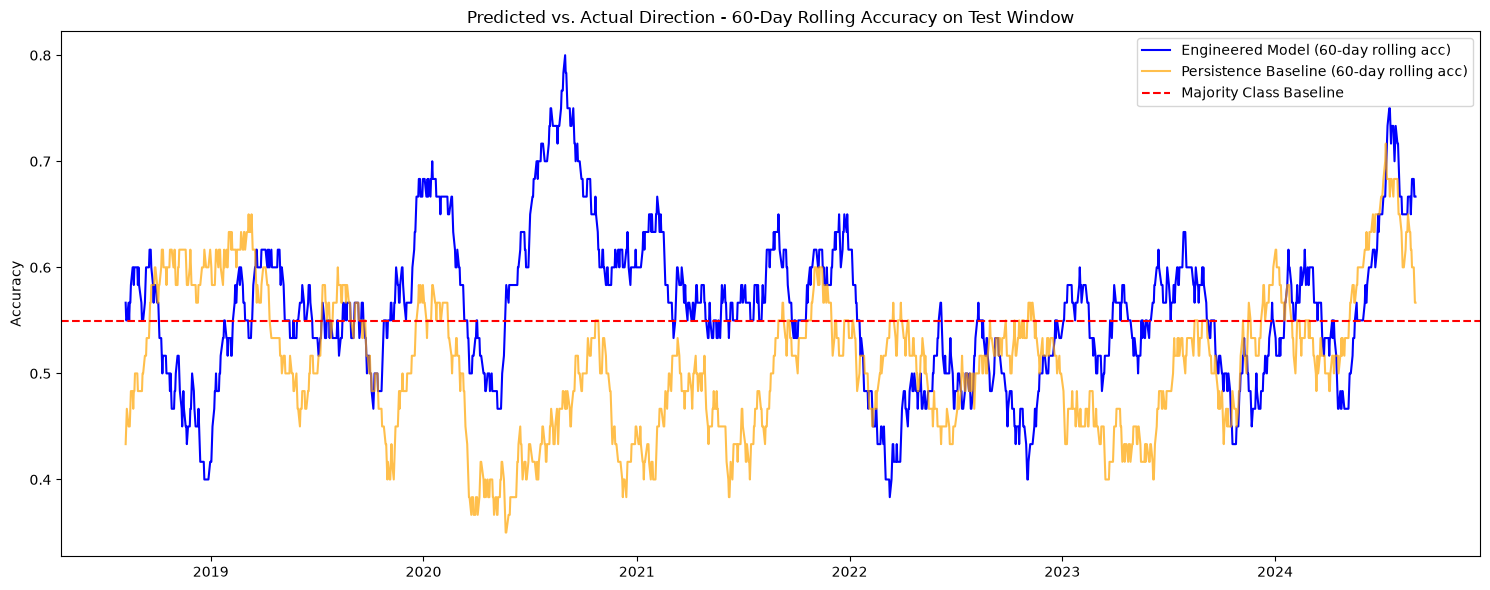

In [7]:
plt.figure(figsize=(15, 6))

# We'll plot the cumulative returns of a strategy that trades based on these predictions
# Strategy return = prediction(1 or 0) * actual_next_day_return
# Wait, the prompt says: "plot predicted vs. actual direction across the test window (time-indexed)."
# Let's plot a rolling accuracy or simply a scatter of predicted vs actual, but since they are 1s and 0s, a scatter might be hard to read.
# Let's plot a 30-day rolling accuracy of the Engineered Model vs Persistence.

test_results = pd.DataFrame({
    'Actual': y_test,
    'Eng_Pred': eng_preds,
    'Persistence_Pred': persistence_preds
}, index=y_test.index)

test_results['Eng_Correct'] = (test_results['Actual'] == test_results['Eng_Pred']).astype(int)
test_results['Pers_Correct'] = (test_results['Actual'] == test_results['Persistence_Pred']).astype(int)

rolling_eng = test_results['Eng_Correct'].rolling(window=60).mean()
rolling_pers = test_results['Pers_Correct'].rolling(window=60).mean()

plt.plot(rolling_eng, label="Engineered Model (60-day rolling acc)", color='blue')
plt.plot(rolling_pers, label="Persistence Baseline (60-day rolling acc)", color='orange', alpha=0.7)
plt.axhline(test_results['Actual'].mean(), color='red', linestyle='--', label='Majority Class Baseline')
plt.title("Predicted vs. Actual Direction - 60-Day Rolling Accuracy on Test Window")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig('predicted_vs_actual.png')
plt.show()